In [3]:
!pip -q install transformers accelerate num2words scikit-learn scipy pandas matplotlib pillow
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [2]:
!wget -q http://www.svcl.ucsd.edu/projects/anomaly/UCSD_Anomaly_Dataset.tar.gz
!tar -xzf UCSD_Anomaly_Dataset.tar.gz

In [4]:
import os, glob, re, gc, time
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = glob.glob("UCSD_Anomaly_Dataset*/UCSDped2/Test")[0]
videos = sorted(d for d in os.listdir(ROOT) if d.startswith("Test") and not d.endswith("_gt"))

data = {}
for v in videos:
    frame_paths = sorted(glob.glob(f"{ROOT}/{v}/*.tif"))
    gt_paths = sorted(glob.glob(f"{ROOT}/{v}_gt/*.bmp"))
    # Ground truth is a pixel mask; a frame is anomalous if any pixel is non-zero
    labels = np.array([int(np.array(Image.open(p)).max() > 0) for p in gt_paths])
    assert len(frame_paths) == len(labels)
    data[v] = {"frames": frame_paths, "labels": labels}

all_labels = np.concatenate([data[v]["labels"] for v in videos])
base_rate = all_labels.mean()
print(f"Total test frames: {len(all_labels)} | anomalous: {base_rate:.1%}")

Total test frames: 2010 | anomalous: 82.0%


In [5]:
from transformers import CLIPModel, CLIPProcessor

clip_name = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(clip_name).to(device).eval()
clip_proc = CLIPProcessor.from_pretrained(clip_name)

def to_tensor(x):
    # Different transformers versions return a tensor or an output object
    return x if torch.is_tensor(x) else x.pooler_output

@torch.no_grad()
def image_features(paths, batch_size=64):
    feats = []
    for i in range(0, len(paths), batch_size):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i+batch_size]]
        inp = clip_proc(images=imgs, return_tensors="pt").to(device)
        f = to_tensor(clip.get_image_features(**inp))
        feats.append(torch.nn.functional.normalize(f, dim=-1).cpu())
    return torch.cat(feats)

@torch.no_grad()
def text_features(prompts):
    inp = clip_proc(text=prompts, return_tensors="pt", padding=True).to(device)
    f = to_tensor(clip.get_text_features(**inp))
    return torch.nn.functional.normalize(f, dim=-1).cpu()

for v in videos:
    data[v]["feats"] = image_features(data[v]["frames"])

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [6]:
from scipy.ndimage import gaussian_filter1d

normal_prompts = ["people walking on a walkway", "pedestrians walking", "an empty walkway"]
anomaly_prompts = ["a person riding a bicycle", "a person riding a skateboard",
                   "a car driving on a walkway", "a person in a wheelchair",
                   "a vehicle on a pedestrian walkway"]

def compute_scores(normal_p, anomaly_p, sigma=3):
    txt = text_features(normal_p + anomaly_p)
    n_norm = len(normal_p)
    out = {}
    for v in videos:
        probs = (100.0 * data[v]["feats"] @ txt.T).softmax(dim=-1)
        score = probs[:, n_norm:].sum(dim=1).numpy()      # total probability of anomaly prompts
        if sigma > 0:
            score = gaussian_filter1d(score, sigma=sigma)  # temporal smoothing
        score = (score - score.min()) / (score.max() - score.min() + 1e-8)  # per-video min-max
        out[v] = score
    return out

scores = compute_scores(normal_prompts, anomaly_prompts, sigma=3)

Frame-level AUC (pooled over all test videos): 0.8816


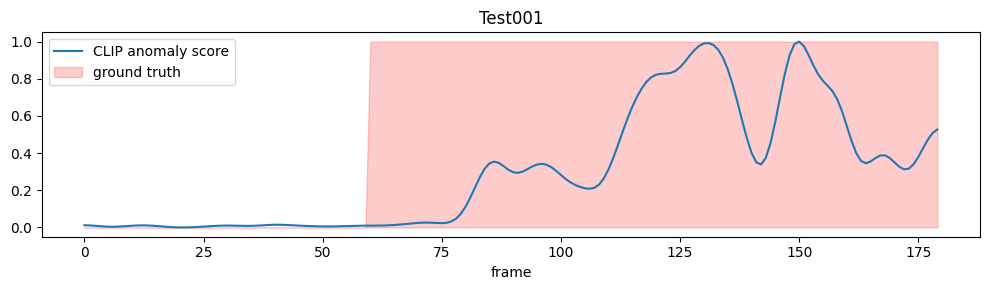

                         setting    AUC
           main prompts, sigma=0 0.8438
           main prompts, sigma=2 0.8693
           main prompts, sigma=3 0.8816
           main prompts, sigma=5 0.8859
           main prompts, sigma=8 0.8883
only bicycle+skateboard, sigma=3 0.8783
   single normal prompt, sigma=3 0.8813


In [7]:
from sklearn.metrics import roc_auc_score

def auc_of(sd):
    return roc_auc_score(all_labels, np.concatenate([sd[v] for v in videos]))

auc_main = auc_of(scores)
print("Frame-level AUC (pooled over all test videos):", round(auc_main, 4))

v = videos[0]
plt.figure(figsize=(10, 3))
plt.plot(scores[v], label="CLIP anomaly score")
plt.fill_between(range(len(scores[v])), 0, data[v]["labels"], color="red", alpha=0.2, label="ground truth")
plt.title(f"{v}"); plt.xlabel("frame"); plt.legend(); plt.tight_layout()
plt.savefig("score_graph.png", dpi=150); plt.show()

rows = [{"setting": f"main prompts, sigma={s}", "AUC": auc_of(compute_scores(normal_prompts, anomaly_prompts, s))}
        for s in [0, 2, 3, 5, 8]]
rows.append({"setting": "only bicycle+skateboard, sigma=3",
             "AUC": auc_of(compute_scores(normal_prompts, ["a person riding a bicycle", "a person riding a skateboard"], 3))})
rows.append({"setting": "single normal prompt, sigma=3",
             "AUC": auc_of(compute_scores(["people walking on a walkway"], anomaly_prompts, 3))})
clip_ablation = pd.DataFrame(rows).round(4)
print(clip_ablation.to_string(index=False))
clip_ablation.to_csv("clip_ablation.csv", index=False)

In [8]:
TOP_K, MIN_GAP = 3, 15   # frames per video, minimum spacing between picks
selected = []
for v in videos:
    s = scores[v]
    chosen = []
    for idx in np.argsort(-s):
        if all(abs(idx - c) >= MIN_GAP for c in chosen):
            chosen.append(int(idx))
        if len(chosen) == TOP_K:
            break
    for idx in chosen:
        selected.append({"video": v, "frame_idx": idx, "path": data[v]["frames"][idx],
                         "clip_score": float(s[idx]), "gt_anomaly": int(data[v]["labels"][idx])})

sel_df = pd.DataFrame(selected)
selection_precision = sel_df["gt_anomaly"].mean()
print(f"Selected {len(sel_df)} frames | precision {selection_precision:.1%} "
      f"(base rate of anomalous frames: {base_rate:.1%})")

Selected 36 frames | precision 97.2% (base rate of anomalous frames: 82.0%)


In [9]:
from transformers import AutoProcessor, AutoModelForImageTextToText

KEYWORDS = (r"\b(bikes?|bicycles?|cyclists?|cycling|bikers?|skateboards?|skateboarders?|skateboarding|"
            r"carts?|cars?|vehicles?|trucks?|vans?|wheelchairs?|motorcycles?|motorbikes?|scooters?)\b")

PROMPTS = {
    "open": ("This is a surveillance camera frame of a pedestrian walkway. "
             "Besides people walking, what vehicle or object is present? Answer in one short sentence."),
    "direct": ("Look carefully. Is there a bicycle, skateboard, car, cart or wheelchair "
               "among the pedestrians? Say which one, in one short sentence."),
}
MODELS = ["HuggingFaceTB/SmolVLM-256M-Instruct",
          "HuggingFaceTB/SmolVLM-500M-Instruct",
          "HuggingFaceTB/SmolVLM-Instruct"]   # 2.2B

def run_vlm(model_name, question, scale=4):
    proc = AutoProcessor.from_pretrained(model_name)
    model = AutoModelForImageTextToText.from_pretrained(
        model_name, torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()
    answers = []
    for item in selected:
        img = Image.open(item["path"]).convert("RGB")
        img = img.resize((img.width * scale, img.height * scale))   # Ped2 frames are tiny, upscale
        msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
        prompt = proc.apply_chat_template(msgs, add_generation_prompt=True)
        inputs = proc(text=prompt, images=[img], return_tensors="pt").to(device)
        if device == "cuda":
            inputs["pixel_values"] = inputs["pixel_values"].to(torch.float16)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=50, do_sample=False)
        answers.append(proc.batch_decode(out[:, inputs["input_ids"].shape[1]:],
                                         skip_special_tokens=True)[0].strip())
    del model, proc
    gc.collect(); torch.cuda.empty_cache()   # free memory before loading the next model
    return answers

results, all_runs = [], {}
for m in MODELS:
    for pname, q in PROMPTS.items():
        t0 = time.time()
        d = sel_df.copy()
        d["explanation"] = run_vlm(m, q)
        d["hit"] = d["explanation"].str.lower().apply(lambda t: bool(re.search(KEYWORDS, t)))
        all_runs[(m, pname)] = d
        # Evaluated only on truly anomalous frames (keyword match, not semantic correctness)
        acc = d[d.gt_anomaly == 1]["hit"].mean()
        results.append({"model": m.split("/")[-1], "prompt": pname,
                        "keyword_match_acc": round(acc, 3), "time_sec": round(time.time() - t0)})
        print(results[-1])

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


...

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

{'model': 'SmolVLM-Instruct', 'prompt': 'open', 'keyword_match_acc': np.float64(0.971), 'time_sec': 168}


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

{'model': 'SmolVLM-Instruct', 'prompt': 'direct', 'keyword_match_acc': np.float64(0.857), 'time_sec': 61}


In [10]:
vlm_table = pd.DataFrame(results)
print(vlm_table.to_string(index=False))
vlm_table.to_csv("vlm_ablation.csv", index=False)
# Note: only 1 of the 36 selected frames is normal, so a false-alarm rate is not meaningful and is not reported.

                model prompt  keyword_match_acc  time_sec
SmolVLM-256M-Instruct   open              0.943        37
SmolVLM-256M-Instruct direct              0.943        36
SmolVLM-500M-Instruct   open              0.914        49
SmolVLM-500M-Instruct direct              0.943        39
     SmolVLM-Instruct   open              0.971       168
     SmolVLM-Instruct direct              0.857        61


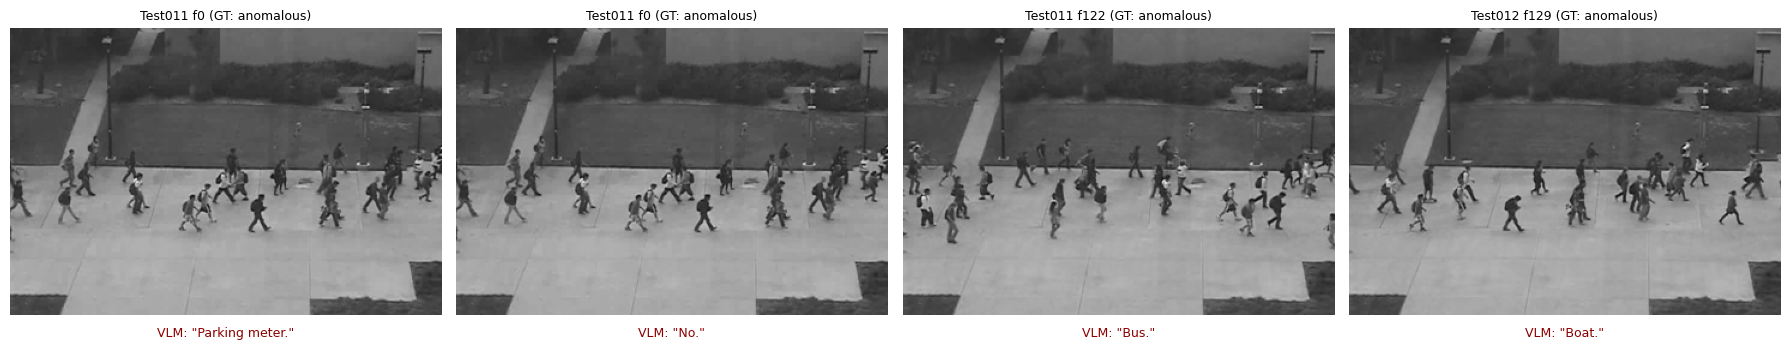

In [11]:
# Collect anomalous frames where the VLM answer contained no anomaly keyword
fails = pd.concat([d[(d.gt_anomaly == 1) & (~d.hit)].assign(run=f"{k[0].split('/')[-1]} / {k[1]}")
                   for k, d in all_runs.items()])
fails = fails.drop_duplicates("explanation")

# Prefer funny/wrong answers like "Parade" or "fighting", then fill with others
fails["pri"] = fails["explanation"].str.lower().str.contains("parade|fight|police|running").astype(int)
fails = fails.sort_values("pri", ascending=False).head(4)

fig, axes = plt.subplots(1, len(fails), figsize=(4.5 * len(fails), 4.2))
axes = np.atleast_1d(axes)
for ax, (_, r) in zip(axes, fails.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{r['video']} f{r['frame_idx']} (GT: anomalous)", fontsize=9)
    ax.text(0.5, -0.04, f"VLM: \"{r['explanation'][:70]}\"", transform=ax.transAxes,
            ha="center", va="top", fontsize=9, color="darkred", wrap=True)
plt.tight_layout(); plt.savefig("failure_cases.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
!zip -q results.zip README.md score_graph.png failure_cases.png clip_ablation.csv vlm_ablation.csv
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Re-add the original open-ended prompt and run it on the same 36 selected frames
PROMPTS["unusual"] = ("This is a surveillance camera frame of a pedestrian walkway. "
                      "What is unusual or abnormal in this frame? Answer in one short sentence.")

m = "HuggingFaceTB/SmolVLM-256M-Instruct"
d = sel_df.copy()
d["explanation"] = run_vlm(m, PROMPTS["unusual"])
d["hit"] = d["explanation"].str.lower().apply(lambda t: bool(re.search(KEYWORDS, t)))
all_runs[(m, "unusual")] = d

# Rebuild the VLM table from all runs (now includes the "unusual" row)
vlm_table = pd.DataFrame([
    {"model": k[0].split("/")[-1], "prompt": k[1],
     "keyword_match_acc": round(r[r.gt_anomaly == 1]["hit"].mean(), 3)}
    for k, r in all_runs.items()
])
print(vlm_table.to_string(index=False))
vlm_table.to_csv("vlm_ablation.csv", index=False)

# Look at a few raw answers
print(d[["video", "frame_idx", "explanation"]].head(10).to_string(index=False))

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

                model  prompt  keyword_match_acc
SmolVLM-256M-Instruct    open              0.943
SmolVLM-256M-Instruct  direct              0.943
SmolVLM-500M-Instruct    open              0.914
SmolVLM-500M-Instruct  direct              0.943
     SmolVLM-Instruct    open              0.971
     SmolVLM-Instruct  direct              0.857
SmolVLM-256M-Instruct unusual              0.200
  video  frame_idx                      explanation
Test001        150              People are running.
Test001        131 People are crossing the walkway.
Test001        116                          Parade.
Test002        150              People are walking.
Test002        135              People are walking.
Test002        165 People are crossing the walkway.
Test003         60                     Motorcycles.
Test003         75     People crossing the walkway.
Test003         38              People are walking.
Test004        169              People are on bike.


In [15]:
# ---- Build the two normal-frame control sets ----
low = []
for v in videos:
    s, lab = scores[v], data[v]["labels"]
    chosen = []
    for idx in np.argsort(s):                      # lowest score first
        if lab[idx] == 1:                          # keep only truly normal frames
            continue
        if all(abs(idx - c) >= MIN_GAP for c in chosen):
            chosen.append(int(idx))
        if len(chosen) == TOP_K:
            break
    for idx in chosen:
        low.append({"video": v, "frame_idx": idx, "path": data[v]["frames"][idx],
                    "clip_score": float(s[idx]), "gt_anomaly": 0, "group": "normal_lowest"})

used = {(r["video"], r["frame_idx"]) for r in low}
pool = [(v, i) for v in videos for i in range(len(data[v]["labels"]))
        if data[v]["labels"][i] == 0 and (v, i) not in used]
rng = np.random.default_rng(0)
rand = []
for j in rng.choice(len(pool), size=len(low), replace=False):
    v, i = pool[j]
    rand.append({"video": v, "frame_idx": i, "path": data[v]["frames"][i],
                 "clip_score": float(scores[v][i]), "gt_anomaly": 0, "group": "normal_random"})

control = pd.DataFrame(low + rand)
print("Normal frames available in test set:", int((all_labels == 0).sum()))
print("Control frames:", control.group.value_counts().to_dict())

# ---- Run the same prompts on the control frames (load each model once) ----
def run_vlm_multi(model_name, prompt_dict, frames_df, scale=4):
    proc = AutoProcessor.from_pretrained(model_name)
    model = AutoModelForImageTextToText.from_pretrained(
        model_name, torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()
    out_all = {}
    for pname, q in prompt_dict.items():
        answers = []
        for path in frames_df["path"]:
            img = Image.open(path).convert("RGB")
            img = img.resize((img.width * scale, img.height * scale))
            msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": q}]}]
            prompt = proc.apply_chat_template(msgs, add_generation_prompt=True)
            inputs = proc(text=prompt, images=[img], return_tensors="pt").to(device)
            if device == "cuda":
                inputs["pixel_values"] = inputs["pixel_values"].to(torch.float16)
            with torch.no_grad():
                out = model.generate(**inputs, max_new_tokens=50, do_sample=False)
            answers.append(proc.batch_decode(out[:, inputs["input_ids"].shape[1]:],
                                             skip_special_tokens=True)[0].strip())
        out_all[pname] = answers
    del model, proc
    gc.collect(); torch.cuda.empty_cache()
    return out_all

# Which prompts were run for which model
model_prompts = {}
for (m, p) in all_runs.keys():
    model_prompts.setdefault(m, {})[p] = PROMPTS[p]

control_runs = {}   # (model, prompt) -> dataframe with answers on control frames
for m, pdict in model_prompts.items():
    print("Running control for", m.split("/")[-1], "| prompts:", list(pdict))
    res = run_vlm_multi(m, pdict, control)
    for p, answers in res.items():
        c = control.copy()
        c["explanation"] = answers
        c["hit"] = c["explanation"].str.lower().apply(lambda t: bool(re.search(KEYWORDS, t)))
        control_runs[(m, p)] = c

# ---- Final comparison table ----
rows = []
for (m, p), c in control_runs.items():
    anom = all_runs[(m, p)]
    anom = anom[anom.gt_anomaly == 1]["hit"].mean()
    rows.append({
        "model": m.split("/")[-1], "prompt": p,
        "hit_on_anomalous": round(anom, 3),
        "hit_on_normal_lowest": round(c[c.group == "normal_lowest"]["hit"].mean(), 3),
        "hit_on_normal_random": round(c[c.group == "normal_random"]["hit"].mean(), 3),
    })
control_table = pd.DataFrame(rows)
control_table["gap_vs_random_normal"] = (control_table["hit_on_anomalous"]
                                         - control_table["hit_on_normal_random"]).round(3)
print(control_table.to_string(index=False))
control_table.to_csv("vlm_control_table.csv", index=False)

Normal frames available in test set: 362
Control frames: {'normal_lowest': 18, 'normal_random': 18}
Running control for SmolVLM-256M-Instruct | prompts: ['open', 'direct', 'unusual']


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Running control for SmolVLM-500M-Instruct | prompts: ['open', 'direct']


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Running control for SmolVLM-Instruct | prompts: ['open', 'direct']


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

                model  prompt  hit_on_anomalous  hit_on_normal_lowest  hit_on_normal_random  gap_vs_random_normal
SmolVLM-256M-Instruct    open             0.943                 0.278                 0.278                 0.665
SmolVLM-256M-Instruct  direct             0.943                 0.778                 0.556                 0.387
SmolVLM-256M-Instruct unusual             0.200                 0.000                 0.000                 0.200
SmolVLM-500M-Instruct    open             0.914                 0.222                 0.167                 0.747
SmolVLM-500M-Instruct  direct             0.943                 0.278                 0.389                 0.554
     SmolVLM-Instruct    open             0.971                 0.889                 1.000                -0.029
     SmolVLM-Instruct  direct             0.857                 0.056                 0.056                 0.801
